In [ ]:
!nvidia-smi

Wed Sep  2 15:51:57 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
# =========================================================
# GitHub model 저장소(dev) 준비
#
# - fresh Colab runtime에서는 저장소를 clone
# - 이미 /content/model에 저장소가 있으면 다시 clone하지 않음
# - GitHub Token은 Colab Secret의 "git_token"에서 읽음
# - Token 문자열은 Notebook에 직접 저장하지 않음
# =========================================================

from google.colab import userdata
import os
import subprocess
import tempfile

repo_dir = "/content/model"

# ---------------------------------------------------------
# 1. 이미 clone된 저장소인지 확인
# ---------------------------------------------------------
if os.path.exists(os.path.join(repo_dir, ".git")):
    print("model repository already exists:", repo_dir)

# ---------------------------------------------------------
# 2. 저장소가 없으면 dev 브랜치 clone
# ---------------------------------------------------------
else:
    # Colab Secret에서 GitHub Token 읽기
    token = userdata.get("git_token")

    if not token:
        raise RuntimeError(
            "Colab Secret에 'git_token'이 등록되어 있지 않습니다."
        )

    # Git 인증용 임시 AskPass 파일 생성
    with tempfile.NamedTemporaryFile(
        mode="w",
        delete=False,
        suffix=".sh",
    ) as f:
        f.write(
            '#!/bin/sh\n'
            'case "$1" in\n'
            '  *Username*) echo "x-access-token" ;;\n'
            '  *Password*) echo "$GITHUB_TOKEN" ;;\n'
            'esac\n'
        )
        askpass = f.name

    os.chmod(askpass, 0o700)

    env = os.environ.copy()
    env["GITHUB_TOKEN"] = token
    env["GIT_ASKPASS"] = askpass
    env["GIT_TERMINAL_PROMPT"] = "0"

    try:
        subprocess.run(
            [
                "git",
                "clone",
                "--branch",
                "dev",
                "https://github.com/brainCDSS/model.git",
                repo_dir,
            ],
            env=env,
            check=True,
        )

    finally:
        # 인증용 임시 파일 제거
        if os.path.exists(askpass):
            os.remove(askpass)

        del token

# ---------------------------------------------------------
# 3. 현재 저장소 상태 확인
# ---------------------------------------------------------
os.chdir(repo_dir)

print("\n현재 위치:", os.getcwd())

print("\n현재 브랜치:")
subprocess.run(
    ["git", "branch", "--show-current"],
    check=True,
)

print("\n현재 최신 커밋:")
subprocess.run(
    ["git", "log", "-1", "--oneline"],
    check=True,
)

model repository already exists: /content/model

현재 위치: /content/model

현재 브랜치:

현재 최신 커밋:


CompletedProcess(args=['git', 'log', '-1', '--oneline'], returncode=0)

In [ ]:
# =========================================================
# Google Cloud 인증
#
# ISLES 2022 전처리 데이터는 GCS에 저장되어 있으므로
# Colab 런타임 시작 시 Google Cloud 계정 인증 필요
#
# ※ GitHub Token 인증과 별개임
# =========================================================

from google.colab import auth

auth.authenticate_user()

print("Google Cloud 인증 완료")



Google Cloud 인증 완료


In [ ]:
# =========================================================
# ISLES 2022 nnU-Net 전처리 데이터 위치 확인
#
# 실제 학습 데이터는 GitHub가 아니라 GCS에서 관리
# I-N00은 아래 nnU-Net preprocessing 결과를 사용
# =========================================================

!gcloud storage ls gs://brainon-cdss-datasets/ischemia/v1/nnunet/

gs://brainon-cdss-datasets/ischemia/v1/nnunet/nnUNet_preprocessed/
gs://brainon-cdss-datasets/ischemia/v1/nnunet/nnUNet_raw/


In [ ]:
# =========================================================
# nnU-Net Colab 작업 경로 설정
#
# - GCS의 전처리 데이터를 Colab 로컬 캐시에 복사해 학습
# - /content 영역은 런타임 종료 시 삭제될 수 있음
# - 학습 checkpoint는 Google Drive에 별도 백업
# =========================================================

import os

# Colab 학습용 로컬 캐시
CACHE_ROOT = "/content/brainon_cache"

os.environ["BRAINON_CACHE_ROOT"] = CACHE_ROOT
os.environ["nnUNet_raw"] = f"{CACHE_ROOT}/nnUNet_raw"
os.environ["nnUNet_preprocessed"] = f"{CACHE_ROOT}/nnUNet_preprocessed"
os.environ["nnUNet_results"] = f"{CACHE_ROOT}/nnUNet_results"

# 필요한 폴더 생성
for path in [
    os.environ["nnUNet_raw"],
    os.environ["nnUNet_preprocessed"],
    os.environ["nnUNet_results"],
]:
    os.makedirs(path, exist_ok=True)

print("nnUNet_raw =", os.environ["nnUNet_raw"])
print("nnUNet_preprocessed =", os.environ["nnUNet_preprocessed"])
print("nnUNet_results =", os.environ["nnUNet_results"])

nnUNet_raw = /content/brainon_cache/nnUNet_raw
nnUNet_preprocessed = /content/brainon_cache/nnUNet_preprocessed
nnUNet_results = /content/brainon_cache/nnUNet_results


In [ ]:
!gcloud storage cp --recursive \
  gs://brainon-cdss-datasets/ischemia/v1/nnunet/nnUNet_preprocessed/Dataset502_ISLES2022 \
  /content/brainon_cache/nnUNet_preprocessed/

Copying gs://brainon-cdss-datasets/ischemia/v1/nnunet/nnUNet_preprocessed/Dataset502_ISLES2022/dataset.json to file:///content/brainon_cache/nnUNet_preprocessed/Dataset502_ISLES2022/dataset.json
Copying gs://brainon-cdss-datasets/ischemia/v1/nnunet/nnUNet_preprocessed/Dataset502_ISLES2022/dataset_fingerprint.json to file:///content/brainon_cache/nnUNet_preprocessed/Dataset502_ISLES2022/dataset_fingerprint.json
Copying gs://brainon-cdss-datasets/ischemia/v1/nnunet/nnUNet_preprocessed/Dataset502_ISLES2022/gt_segmentations/sub-strokecase0001.nii.gz to file:///content/brainon_cache/nnUNet_preprocessed/Dataset502_ISLES2022/gt_segmentations/sub-strokecase0001.nii.gz
Copying gs://brainon-cdss-datasets/ischemia/v1/nnunet/nnUNet_preprocessed/Dataset502_ISLES2022/gt_segmentations/sub-strokecase0002.nii.gz to file:///content/brainon_cache/nnUNet_preprocessed/Dataset502_ISLES2022/gt_segmentations/sub-strokecase0002.nii.gz
Copying gs://brainon-cdss-datasets/ischemia/v1/nnunet/nnUNet_preprocessed/Da

In [ ]:
# =========================================================
# ISLES 2022 nnU-Net 전처리 데이터 검증
#
# GCS에서 Colab 로컬 캐시로 복사한 Dataset502_ISLES2022가
# 학습에 필요한 파일 구조를 정상적으로 갖추고 있는지 확인
#
# 확인 항목
# - dataset.json
# - dataset_fingerprint.json
# - nnUNetPlans.json
# - splits_final.json
# - 3d_fullres 전처리 데이터(.b2nd)
# - Case별 properties 파일(.pkl)
# - Fold 0 Train / Validation Case 수
#
# ※ 실제 학습은 아래 Colab 캐시의 전처리 데이터를 사용
# =========================================================

from pathlib import Path
import json

root = Path(
    "/content/brainon_cache/nnUNet_preprocessed/Dataset502_ISLES2022"
)

print("Dataset 폴더:", root.exists())
print("dataset.json:", (root / "dataset.json").exists())
print("dataset_fingerprint.json:", (root / "dataset_fingerprint.json").exists())
print("nnUNetPlans.json:", (root / "nnUNetPlans.json").exists())
print("splits_final.json:", (root / "splits_final.json").exists())

fullres = root / "nnUNetPlans_3d_fullres"

print("\n3d_fullres 폴더:", fullres.exists())
print("data(.b2nd):", len(list(fullres.glob("sub-strokecase*.b2nd"))))
print("properties(.pkl):", len(list(fullres.glob("*.pkl"))))

with open(root / "splits_final.json", encoding="utf-8") as f:
    splits = json.load(f)

print("\nFold 수:", len(splits))
print("Fold 0 Train:", len(splits[0]["train"]))
print("Fold 0 Val:", len(splits[0]["val"]))

Dataset 폴더: True
dataset.json: True
dataset_fingerprint.json: True
nnUNetPlans.json: True
splits_final.json: True

3d_fullres 폴더: True
data(.b2nd): 426
properties(.pkl): 213

Fold 수: 1
Fold 0 Train: 175
Fold 0 Val: 38


In [ ]:
# =========================================================
# I-N00 학습 환경 사전 점검 (Preflight Check)
#
# 학습 환경 구성을 진행하기 전에 다음 항목을 확인
# - GitHub model 저장소 및 dev branch
# - Dataset502_ISLES2022 전처리 데이터
# - nnU-Net split 및 3d_fullres 데이터
# - Colab CUDA / GPU 사용 가능 여부
# =========================================================

from pathlib import Path
import subprocess
import torch

repo = Path("/content/model")
data = Path(
    "/content/brainon_cache/nnUNet_preprocessed/Dataset502_ISLES2022"
)

print("=== GitHub 코드 ===")
print("/content/model 존재:", repo.exists())

if (repo / ".git").exists():
    branch = subprocess.check_output(
        ["git", "-C", str(repo), "branch", "--show-current"],
        text=True
    ).strip()
    print("Git branch:", branch)
else:
    print("Git 저장소 확인 필요")

print("\n=== nnU-Net 데이터 ===")
print("Dataset502 존재:", data.exists())
print("splits_final.json:", (data / "splits_final.json").exists())
print(
    "3d_fullres b2nd:",
    len(list((data / "nnUNetPlans_3d_fullres").glob("*.b2nd")))
    if data.exists() else 0
)

print("\n=== GPU ===")
print("CUDA:", torch.cuda.is_available())
print(
    "GPU:",
    torch.cuda.get_device_name(0)
    if torch.cuda.is_available() else "None"
)

=== GitHub 코드 ===
/content/model 존재: True
Git branch: dev

=== nnU-Net 데이터 ===
Dataset502 존재: True
splits_final.json: True
3d_fullres b2nd: 426

=== GPU ===
CUDA: True
GPU: Tesla T4


In [ ]:
# I-N00 nnU-Net 학습 환경 요구사항 확인

%cd /content/model

!grep -n "requires-python" pyproject.toml
!echo "----- nnU-Net requirements -----"
!cat requirements-nnunet-cu130.txt

/content
10:requires-python = ">=3.10,<3.13"
----- nnU-Net requirements -----
# Target environment: Python 3.12 / Windows / NVIDIA RTX 4060 Ti / CUDA 13.0
# The CUDA-enabled PyTorch wheel supplies its matching CUDA runtime libraries.
--extra-index-url https://download.pytorch.org/whl/cu130

# Core frameworks
torch==2.13.0+cu130
nnunetv2==2.8.1
monai==1.6.0

# Numerical / data
numpy==2.5.2
scipy==1.18.1
pandas==3.0.5
scikit-learn==1.9.0
scikit-image==0.26.0

# Medical imaging
SimpleITK==2.5.6
nibabel==5.4.2
ImageIO==2.37.4

# nnU-Net dependencies
batchgenerators==0.25.3
batchgeneratorsv2==0.3.5
acvl_utils==0.2.6
dynamic_network_architectures==0.4.4
connected-components-3d==4.1.0
blosc2==4.11.0

# Training utilities
tqdm==4.70.0
tensorboard==2.21.0
einops==0.8.2
timm==1.0.22

# Visualization and notebook monitoring
matplotlib==3.11.1
seaborn==0.13.2
jupyterlab>=4,<5
ipywidgets>=8,<9

# Config / utility
PyYAML==6.0.3
packaging==26.3


In [ ]:
# Python 3.12 학습환경 생성
!python -m pip install -q uv

# Python 3.12 설치
!uv python install 3.12

# brainCDSS 모델 학습용 가상환경 생성
!uv venv /content/brainon_py312 --python 3.12

# 버전 확인
!/content/brainon_py312/bin/python --version

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.1/20.1 MB 90.7 MB/s eta 0:00:00
Installed Python 3.12.14 in 2.00s
 + cpython-3.12.14-linux-x86_64-gnu (python3.12)
Using CPython 3.12.14
Creating virtual environment at: /content/brainon_py312
Activate with: source /content/brainon_py312/bin/activate
Python 3.12.14


In [ ]:
from pathlib import Path

print("/content/model 존재:",
      Path("/content/model").exists())

print("requirements 존재:",
      Path("/content/model/requirements-nnunet-cu130.txt").exists())

/content/model 존재: True
requirements 존재: True


In [ ]:
!uv pip install \
  --python /content/brainon_py312/bin/python \
  --index-strategy unsafe-best-match \
  -r /content/model/requirements-nnunet-cu130.txt

Using Python 3.12.14 environment at: /content/brainon_py312
Resolved 185 packages in 1.82s
Prepared 185 packages in 53.16s
Installed 185 packages in 1.21s
 + absl-py==2.5.0
 + acvl-utils==0.2.6
 + annotated-types==0.8.0
 + anyio==4.14.2
 + argon2-cffi==25.1.0
 + argon2-cffi-bindings==26.1.0
 + argparse==1.4.0
 + arrow==1.4.0
 + asttokens==3.0.2
 + async-lru==2.3.0
 + attrs==26.1.0
 + babel==2.18.0
 + batchgenerators==0.25.3
 + batchgeneratorsv2==0.3.5
 + beautifulsoup4==4.15.0
 + bleach==6.4.0
 + blosc2==4.11.0
 + certifi==2026.7.22
 + cffi==2.1.1
 + charset-normalizer==3.5.1
 + click==8.5.0
 + cloudpickle==3.1.2
 + comm==0.2.3
 + connected-components-3d==4.1.0
 + contourpy==1.3.3
 + cuda-bindings==13.3.1
 + cuda-pathfinder==1.8.0
 + cuda-toolkit==13.0.3.0
 + cycler==0.12.1
 + debugpy==1.8.21
 + defusedxml==0.7.1
 + dynamic-network-architectures==0.4.4
 + einops==0.8.2
 + executing==2.2.1
 + fastjsonschema==2.22.2
 + filelock==3.32.5
 + fonttools==4.64.0
 + fqdn==1.5.1
 + fsspec==2026.

In [ ]:
# =========================================================
# I-N00 nnU-Net 학습 환경 검증
#
# Python 3.12 가상환경에 설치된 주요 패키지 버전과
# CUDA/GPU 사용 가능 여부를 확인
#
# 마지막에는 실제 CUDA tensor 연산을 수행하여
# GPU 학습 환경이 정상적으로 구성됐는지 검증
# =========================================================

%%bash

/content/brainon_py312/bin/python - <<'PY'
import sys
import torch
import monai
import numpy as np
from importlib.metadata import version

print("=== Environment ===")
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("PyTorch CUDA:", torch.version.cuda)
print("nnUNetv2:", version("nnunetv2"))
print("MONAI:", monai.__version__)
print("NumPy:", np.__version__)

print("\n=== GPU ===")
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Compute capability:", torch.cuda.get_device_capability(0))
    print(
        "VRAM:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )

    # 실제 GPU 연산 확인
    x = torch.randn(512, 512, device="cuda")
    y = x @ x

    print("CUDA tensor:", y.device)
    print("CUDA operation: PASS")
PY

=== Environment ===
Python: 3.12.14
PyTorch: 2.13.0+cu130
PyTorch CUDA: 13.0
nnUNetv2: 2.8.1
MONAI: 1.6.0
NumPy: 2.5.2

=== GPU ===
CUDA available: True
GPU: Tesla T4
Compute capability: (7, 5)
VRAM: 14.56 GB
CUDA tensor: cuda:0
CUDA operation: PASS


In [ ]:
# =========================================================
# brainCDSS 모델 패키지 설치
#
# GitHub에서 clone한 /content/model 소스 코드를
# Python 3.12 학습환경에 editable mode로 설치
#
# 외부 dependency는 앞 단계에서 이미 설치했으므로
# --no-deps 옵션 사용
# =========================================================

!uv pip install \
  --python /content/brainon_py312/bin/python \
  --no-deps \
  -e /content/model

Using Python 3.12.14 environment at: /content/brainon_py312
Resolved 1 package in 1ms
Prepared 1 package in 580ms
Installed 1 package in 1ms
 + brainon-ai==0.1.0 (from file:///content/model)


In [ ]:
# =========================================================
# I-N00 학습 실행 전 최종 환경 점검
#
# - brainon_ai 패키지 import
# - nnUNetv2 설치 상태
# - Dataset502 전처리 데이터
# - 3d_fullres / split 파일
# - nnUNetv2_train 실행 명령
#
# 실제 학습을 시작하기 전에 필요한 구성요소를 최종 확인
# =========================================================

%%bash

export nnUNet_raw=/content/brainon_cache/nnUNet_raw
export nnUNet_preprocessed=/content/brainon_cache/nnUNet_preprocessed
export nnUNet_results=/content/brainon_cache/nnUNet_results

echo "=== brainon-ai ==="
/content/brainon_py312/bin/python -c "import brainon_ai; print('brainon_ai import: PASS')"

echo
echo "=== nnU-Net ==="
/content/brainon_py312/bin/python -c "from importlib.metadata import version; print('nnunetv2:', version('nnunetv2'))"

echo
echo "=== Dataset502 ==="
/content/brainon_py312/bin/python - <<'PY'
from pathlib import Path

p = Path("/content/brainon_cache/nnUNet_preprocessed/Dataset502_ISLES2022")
print("Dataset502:", p.exists())
print("3d_fullres:", (p / "nnUNetPlans_3d_fullres").exists())
print("splits_final:", (p / "splits_final.json").exists())
PY

echo
echo "=== nnUNet train command ==="
test -x /content/brainon_py312/bin/nnUNetv2_train \
  && echo "nnUNetv2_train: PASS" \
  || echo "nnUNetv2_train: NOT FOUND"

=== brainon-ai ===
brainon_ai import: PASS

=== nnU-Net ===
nnunetv2: 2.8.1

=== Dataset502 ===
Dataset502: True
3d_fullres: True
splits_final: True

=== nnUNet train command ===
nnUNetv2_train: PASS


In [ ]:
# =========================================================
# Google Drive 마운트
#
# I-N00 학습 checkpoint를 런타임 종료 후에도
# 보존하기 위해 Google Drive 연결
# =========================================================

from google.colab import drive
drive.mount('/content/gdrive', force_remount=True)

Mounted at /content/gdrive


In [ ]:
!ls -lh "/content/gdrive/MyDrive/brainCDSS/checkpoints/I-N00/fold_0"

total 380M
-rw------- 1 root root 127M Sep  1 09:55 checkpoint_best.pth
-rw------- 1 root root 127M Sep  1 11:44 checkpoint_final.pth
-rw------- 1 root root 127M Sep  1 11:44 checkpoint_latest.pth
-rw------- 1 root root  155 Sep  1 11:44 early_stopping_state.json


In [ ]:
# Checkpoint 저장 경로 설정

from pathlib import Path

checkpoint_dir = Path(
    "/content/gdrive/MyDrive/brainCDSS/checkpoints/I-N00"
)

checkpoint_dir.mkdir(parents=True, exist_ok=True)

print("Checkpoint directory:", checkpoint_dir)
print("Exists:", checkpoint_dir.exists())

Checkpoint directory: /content/gdrive/MyDrive/brainCDSS/checkpoints/I-N00
Exists: True


In [ ]:
from pathlib import Path
import shutil

# Google Drive에 저장된 checkpoint
src = Path(
    "/content/gdrive/MyDrive/brainCDSS/checkpoints/I-N00/fold_0"
)

# nnU-Net이 실제로 확인하는 로컬 결과 폴더
dst = Path(
    "/content/brainon_cache/nnUNet_results/"
    "Dataset502_ISLES2022/"
    "nnUNetTrainerIschemiaBaseline__nnUNetPlans__3d_fullres/"
    "fold_0"
)

dst.mkdir(parents=True, exist_ok=True)

files = [
    "checkpoint_best.pth",
    "checkpoint_final.pth",
    "checkpoint_latest.pth",
    "early_stopping_state.json",
]

for name in files:
    shutil.copy2(src / name, dst / name)
    print(name, "복구 완료")

print("\n=== LOCAL CHECK ===")
for name in files:
    print(name, (dst / name).exists()) ###########################################

checkpoint_best.pth 복구 완료
checkpoint_final.pth 복구 완료
checkpoint_latest.pth 복구 완료
early_stopping_state.json 복구 완료

=== LOCAL CHECK ===
checkpoint_best.pth True
checkpoint_final.pth True
checkpoint_latest.pth True
early_stopping_state.json True


In [ ]:
%%bash

# =========================================================
# I-N00 학습 결과 및 Checkpoint 백업 확인
#
# - Colab 로컬 nnUNet_results 확인
# - Google Drive checkpoint 백업 확인
# - 최근 training log 확인
# =========================================================

RESULT="/content/brainon_cache/nnUNet_results/Dataset502_ISLES2022/nnUNetTrainerIschemiaBaseline__nnUNetPlans__3d_fullres/fold_0"
DRIVE="/content/gdrive/MyDrive/brainCDSS/checkpoints/I-N00/fold_0"


echo "=== LOCAL RESULT ==="
if [ -d "$RESULT" ]; then
    ls -lah "$RESULT"
else
    echo "현재 런타임에 local 결과 폴더 없음"
fi

echo
echo "=== DRIVE CHECKPOINT ==="
if [ -d "$DRIVE" ]; then
    ls -lah "$DRIVE"
else
    echo "Drive checkpoint 폴더 없음"
fi

echo
echo "=== TRAINING LOG ==="
if [ -d "$RESULT" ]; then
    find "$RESULT" \
        -maxdepth 1 \
        -type f \
        -name "*.txt" \
        -print \
        -exec tail -n 20 {} \;
else
    echo "현재 런타임에 확인할 training log 없음"
fi

=== LOCAL RESULT ===
total 20K
drwxr-xr-x 2 root root 4.0K Sep  2 06:12 .
drwxr-xr-x 3 root root 4.0K Sep  2 05:59 ..
-rw-r--r-- 1 root root  404 Sep  2 05:59 training_log_2026_9_2_05_59_30.txt
-rw-r--r-- 1 root root  404 Sep  2 06:11 training_log_2026_9_2_06_11_13.txt
-rw-r--r-- 1 root root  404 Sep  2 06:12 training_log_2026_9_2_06_12_38.txt

=== DRIVE CHECKPOINT ===
total 380M
-rw------- 1 root root 127M Sep  1 09:55 checkpoint_best.pth
-rw------- 1 root root 127M Sep  1 11:44 checkpoint_final.pth
-rw------- 1 root root 127M Sep  1 11:44 checkpoint_latest.pth
-rw------- 1 root root  155 Sep  1 11:44 early_stopping_state.json

=== TRAINING LOG ===
/content/brainon_cache/nnUNet_results/Dataset502_ISLES2022/nnUNetTrainerIschemiaBaseline__nnUNetPlans__3d_fullres/fold_0/training_log_2026_9_2_06_11_13.txt

#######################################################################
Please cite the following paper when using nnU-Net:
Isensee, F., Jaeger, P. F., Kohl, S. A., Petersen, J., & Maie

In [ ]:
import os
import re
import subprocess
from tqdm.notebook import tqdm

# =========================================================
# 환경 설정
# =========================================================

env = os.environ.copy()

env["nnUNet_raw"] = "/content/brainon_cache/nnUNet_raw"
env["nnUNet_preprocessed"] = "/content/brainon_cache/nnUNet_preprocessed"
env["nnUNet_results"] = "/content/brainon_cache/nnUNet_results"

env["nnUNet_extTrainer"] = (
    "/content/model/src/brainon_ai/nnunet/trainers"
)

env["BRAINON_EXPERIMENT_CONFIG"] = (
    "/content/model/configs/experiments/ischemia/I-N00.yaml"
)

env["BRAINON_CHECKPOINT_DIR"] = (
    "/content/gdrive/MyDrive/brainCDSS/checkpoints/I-N00"
)

env["PYTHONUNBUFFERED"] = "1"


# =========================================================
# 학습 명령
# =========================================================

cmd = [
    "/content/brainon_py312/bin/nnUNetv2_train",
    "502",
    "3d_fullres",
    "0",
    "-tr", "nnUNetTrainerIschemiaBaseline",
    "-p", "nnUNetPlans",
    "--c",
    "--val_best",
    "-device", "cuda",
]


print("=" * 60)
print("I-N00 학습을 checkpoint에서 재개합니다.")
print("=" * 60)


# =========================================================
# nnU-Net 실행
# =========================================================

process = subprocess.Popen(
    cmd,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1,
    env=env,
)


# =========================================================
# 화면에 표시할 게이지바 하나
# =========================================================

progress = tqdm(
    total=250,
    desc="학습 준비 중",
    unit="it",
)

current_epoch = None
phase = None


# =========================================================
# nnU-Net 출력 읽기
# =========================================================

for raw_line in iter(process.stdout.readline, ""):

    line = raw_line.strip()

    # -----------------------------------------------------
    # Resume 정보는 출력
    # -----------------------------------------------------
    if line.startswith("[Resume]"):
        print(line)
        continue


    # -----------------------------------------------------
    # 현재 Epoch 찾기
    # 예: Epoch 8/300
    # -----------------------------------------------------
    epoch_match = re.fullmatch(
        r"Epoch\s+(\d+)/300",
        line,
    )

    if epoch_match:
        current_epoch = int(
            epoch_match.group(1)
        )
        continue


    # -----------------------------------------------------
    # TRAIN 시작
    # -----------------------------------------------------
    if line == "[TRAIN]":

        phase = "TRAIN"

        progress.reset(
            total=250
        )

        progress.set_description(
            f"Epoch {current_epoch}/300 | TRAIN"
        )

        progress.set_postfix_str(
            "시작"
        )

        continue


    # -----------------------------------------------------
    # VALIDATION 시작
    # -----------------------------------------------------
    if line == "[VALIDATION]":

        phase = "VAL"

        progress.reset(
            total=50
        )

        progress.set_description(
            f"Epoch {current_epoch}/300 | VAL"
        )

        progress.set_postfix_str(
            "시작"
        )

        continue


    # -----------------------------------------------------
    # Trainer에서 출력한 진행상황 파싱
    #
    # 예:
    # [██░░...] 20/250 (8.0%)
    # | loss -0.7727
    # | avg -0.6884
    # | ETA 00:06:57
    # -----------------------------------------------------
    if phase is not None and line.startswith("["):

        progress_match = re.search(
            r"\]\s*"
            r"(\d+)/(\d+)"
            r"\s*\("
            r"\s*[\d.]+%"
            r"\)"
            r".*?"
            r"loss\s+([-\d.]+)"
            r".*?"
            r"avg\s+([-\d.]+)"
            r".*?"
            r"ETA\s+(\S+)",
            line,
        )

        if progress_match:

            current = int(
                progress_match.group(1)
            )

            total = int(
                progress_match.group(2)
            )

            loss = progress_match.group(3)
            avg_loss = progress_match.group(4)
            eta = progress_match.group(5)

            # 같은 게이지바만 갱신
            progress.total = total
            progress.n = current

            progress.set_description(
                f"Epoch {current_epoch}/300 | {phase}"
            )

            progress.set_postfix_str(
                f"loss={loss} | "
                f"avg={avg_loss} | "
                f"ETA={eta}"
            )

            progress.refresh()

            continue


    # -----------------------------------------------------
    # Epoch 종료 결과만 출력
    # -----------------------------------------------------
    important_results = (
        "완료",
        "Train Loss",
        "Val Loss",
        "Validation Dice",
        "Best Dice",
        "Early Stopping",
        "Learning Rate",
        "Epoch Time",
        "Estimated Left",
        "New Best",
        "checkpoint_latest",
        "Early Stopping triggered",
    )

    if any(
        key in line
        for key in important_results
    ):
        print(line)


# =========================================================
# 종료
# =========================================================

process.stdout.close()

return_code = process.wait()

progress.close()

print()
print(
    "학습 프로세스 종료 코드:",
    return_code,
)

I-N00 학습을 checkpoint에서 재개합니다.


학습 준비 중:   0%|          | 0/250 [00:00<?, ?it/s]

[Resume] 현재 Epoch: 12
[Resume] Best Dice: 0.8282
[Resume] Early Stopping: 4/30
Epoch 13/300 완료
Train Loss        : -0.7365
Val Loss          : -0.7372
Validation Dice   : 0.8299
Best Dice         : 0.8299 (Epoch 13)
Early Stopping    : 0/30
Learning Rate     : 0.00963927
Epoch Time        : 00:04:09
Estimated Left    : 19:54:17
★ New Best Validation Dice → checkpoint_best.pth 저장 완료
✓ checkpoint_latest.pth → Google Drive 백업 완료
Epoch 14/300 완료
Train Loss        : -0.7314
Val Loss          : -0.7265
Validation Dice   : 0.8313
Best Dice         : 0.8313 (Epoch 14)
Early Stopping    : 0/30
Learning Rate     : 0.00960914
Epoch Time        : 00:03:38
Estimated Left    : 18:36:35
★ New Best Validation Dice → checkpoint_best.pth 저장 완료
✓ checkpoint_latest.pth → Google Drive 백업 완료
Epoch 15/300 완료
Train Loss        : -0.7363
Val Loss          : -0.7253
Validation Dice   : 0.8324
Best Dice         : 0.8324 (Epoch 15)
Early Stopping    : 0/30
Learning Rate     : 0.00957900
Epoch Time        : 00:03:

In [ ]:
import json
from pathlib import Path

candidates = list(Path("/content").rglob("dataset.json"))

for p in candidates:
    if "Dataset502_ISLES2022" in str(p):
        print("PATH:", p)
        with open(p, "r") as f:
            data = json.load(f)
        print("channel_names:", data.get("channel_names"))

In [ ]:
%%bash

grep -R -l \
"class nnUNetTrainerIschemiaBaseline" \
/content/model \
/content/src \
/content/brainon* \
2>/dev/null | head -20

In [ ]:
from pathlib import Path
import shutil

PRE = Path("/content/brainon_cache/nnUNet_preprocessed/Dataset502_ISLES2022")

MODEL = Path(
    "/content/brainon_cache/nnUNet_results/"
    "Dataset502_ISLES2022/"
    "nnUNetTrainerIschemiaBaseline__nnUNetPlans__3d_fullres"
)

MODEL.mkdir(parents=True, exist_ok=True)

# dataset.json 복사
src_dataset = PRE / "dataset.json"
dst_dataset = MODEL / "dataset.json"

if not src_dataset.exists():
    raise FileNotFoundError(src_dataset)

shutil.copy2(src_dataset, dst_dataset)

# nnUNetPlans.json -> plans.json 으로 복사
src_plans = PRE / "nnUNetPlans.json"
dst_plans = MODEL / "plans.json"

if not src_plans.exists():
    raise FileNotFoundError(src_plans)

shutil.copy2(src_plans, dst_plans)

print("=== 추론용 메타데이터 준비 완료 ===")
print("dataset.json :", dst_dataset.exists(), dst_dataset)
print("plans.json   :", dst_plans.exists(), dst_plans)

ckpt = MODEL / "fold_0" / "checkpoint_best.pth"
print("checkpoint   :", ckpt.exists(), ckpt)

=== 추론용 메타데이터 준비 완료 ===
dataset.json : True /content/brainon_cache/nnUNet_results/Dataset502_ISLES2022/nnUNetTrainerIschemiaBaseline__nnUNetPlans__3d_fullres/dataset.json
plans.json   : True /content/brainon_cache/nnUNet_results/Dataset502_ISLES2022/nnUNetTrainerIschemiaBaseline__nnUNetPlans__3d_fullres/plans.json
checkpoint   : True /content/brainon_cache/nnUNet_results/Dataset502_ISLES2022/nnUNetTrainerIschemiaBaseline__nnUNetPlans__3d_fullres/fold_0/checkpoint_best.pth


In [ ]:
from pathlib import Path

fold = Path(
    "/content/brainon_cache/nnUNet_results/"
    "Dataset502_ISLES2022/"
    "nnUNetTrainerIschemiaBaseline__nnUNetPlans__3d_fullres/"
    "fold_0"
)

print("=== checkpoint 확인 ===")
for f in sorted(fold.glob("checkpoint*.pth")):
    print(f.name)

=== checkpoint 확인 ===
checkpoint_best.pth
checkpoint_final.pth
checkpoint_latest.pth


In [ ]:
%%bash

export nnUNet_raw=/content/brainon_cache/nnUNet_raw
export nnUNet_preprocessed=/content/brainon_cache/nnUNet_preprocessed
export nnUNet_results=/content/brainon_cache/nnUNet_results

export nnUNet_extTrainer=/content/model/src/brainon_ai/nnunet/trainers

export BRAINON_EXPERIMENT_CONFIG=/content/model/configs/experiments/ischemia/I-N00.yaml

export BRAINON_CHECKPOINT_DIR=/content/gdrive/MyDrive/brainCDSS/checkpoints/I-N00

echo "=== nnU-Net Validation 시작 ==="

/content/brainon_py312/bin/nnUNetv2_train \
  502 \
  3d_fullres \
  0 \
  -tr nnUNetTrainerIschemiaBaseline \
  -p nnUNetPlans \
  --val \
  --val_best \
  -device cuda

=== nnU-Net Validation 시작 ===

############################
INFO: You are using the old nnU-Net default plans. We have updated our recommendations. Please consider using those instead! Read more here: https://github.com/MIC-DKFZ/nnUNet/blob/master/documentation/resenc_presets.md
############################

Trainer 'nnUNetTrainerIschemiaBaseline' not found in nnunetv2.training.nnUNetTrainer.
Searching in external trainer paths from environment variable 'nnUNet_extTrainer'...
Searching in: /content/model/src/brainon_ai/nnunet/trainers
Searching for class nnUNetTrainerIschemiaBaseline in folder /content/model/src/brainon_ai/nnunet/trainers with current module None
  Inspecting module: configurable_trainer
  Inspecting module: nnUNetTrainerAneurysmEarlyStopping
  Inspecting module: nnUNetTrainerIschemiaBaseline
Found class nnUNetTrainerIschemiaBaseline in nnUNetTrainerIschemiaBaseline
Using trainer 'nnUNetTrainerIschemiaBaseline' from: /content/model/src/brainon_ai/nnunet/trainers
Using 

W0902 15:59:01.911000 14869 torch/_inductor/utils.py:1953] [0/0] Not enough SMs to use max_autotune_gemm mode


In [ ]:
from pathlib import Path

VAL_DIR = Path(
    "/content/brainon_cache/nnUNet_results/"
    "Dataset502_ISLES2022/"
    "nnUNetTrainerIschemiaBaseline__nnUNetPlans__3d_fullres/"
    "fold_0/validation"
)

print("Validation 폴더:", VAL_DIR.exists())

for f in VAL_DIR.glob("*.json"):
    print(f.name)

Validation 폴더: True
summary.json


In [ ]:
import json
from pathlib import Path

VAL_DIR = Path(
    "/content/brainon_cache/nnUNet_results/"
    "Dataset502_ISLES2022/"
    "nnUNetTrainerIschemiaBaseline__nnUNetPlans__3d_fullres/"
    "fold_0/validation"
)

summary_path = VAL_DIR / "summary.json"

with open(summary_path, "r") as f:
    summary = json.load(f)

print("summary keys:", summary.keys())
print("case 수:", len(summary.get("metric_per_case", [])))
print()

# 첫 번째 환자 결과 구조 확인
print(json.dumps(summary["metric_per_case"][0], indent=2)[:3000])

summary keys: dict_keys(['foreground_mean', 'mean', 'metric_per_case'])
case 수: 38

{
  "metrics": {
    "1": {
      "Dice": 0.8923076923076924,
      "FN": 2,
      "FP": 26,
      "IoU": 0.8055555555555556,
      "TN": 903024,
      "TP": 116,
      "n_pred": 142,
      "n_ref": 118
    }
  },
  "prediction_file": "/content/brainon_cache/nnUNet_results/Dataset502_ISLES2022/nnUNetTrainerIschemiaBaseline__nnUNetPlans__3d_fullres/fold_0/validation/sub-strokecase0002.nii.gz",
  "reference_file": "/content/brainon_cache/nnUNet_preprocessed/Dataset502_ISLES2022/gt_segmentations/sub-strokecase0002.nii.gz"
}


In [ ]:
import json
import numpy as np
import pandas as pd
import nibabel as nib
from pathlib import Path

VAL_DIR = Path(
    "/content/brainon_cache/nnUNet_results/"
    "Dataset502_ISLES2022/"
    "nnUNetTrainerIschemiaBaseline__nnUNetPlans__3d_fullres/"
    "fold_0/validation"
)

summary_path = VAL_DIR / "summary.json"

with open(summary_path, "r") as f:
    summary = json.load(f)

rows = []

for item in summary["metric_per_case"]:
    m = item["metrics"]["1"]

    ref_path = Path(item["reference_file"])
    case_id = ref_path.name.replace(".nii.gz", "")

    dice = m["Dice"]
    n_ref = m["n_ref"]
    n_pred = m["n_pred"]

    # 실제 voxel 크기(mm) 확인
    nii = nib.load(ref_path)
    spacing = nii.header.get_zooms()[:3]
    voxel_volume_mm3 = np.prod(spacing)

    # 실제 병변 부피 mL
    lesion_volume_ml = n_ref * voxel_volume_mm3 / 1000.0

    # 병변 크기 그룹
    if n_ref == 0:
        size_group = "Empty-GT"
    elif lesion_volume_ml < 5:
        size_group = "Small"
    elif lesion_volume_ml < 20:
        size_group = "Medium"
    else:
        size_group = "Large"

    rows.append({
        "case": case_id,
        "dice": dice,
        "gt_voxels": n_ref,
        "pred_voxels": n_pred,
        "lesion_volume_ml": lesion_volume_ml,
        "size_group": size_group
    })

df_val = pd.DataFrame(rows)

# 병변 존재 Case
lesion_df = df_val[df_val["gt_voxels"] > 0].copy()

print("========================================")
print(" nnU-Net VALIDATION CASE-WISE RESULT")
print("========================================")
print("전체 Validation Case :", len(df_val))
print("병변 존재 Case       :", len(lesion_df))
print("Empty-GT Case        :", (df_val["gt_voxels"] == 0).sum())

print("\n환자별 Dice")
print(
    df_val[
        ["case", "lesion_volume_ml", "size_group", "dice"]
    ].sort_values("lesion_volume_ml").to_string(index=False)
)

print("\n========================================")
print(" VALIDATION MACRO DICE")
print("========================================")

macro_dice = lesion_df["dice"].mean()

print(f"Lesion-positive Macro Dice : {macro_dice:.4f}")

print("\n--- Lesion Size별 Macro Dice ---")

size_summary = (
    lesion_df
    .groupby("size_group")
    .agg(
        cases=("case", "count"),
        volume_min_ml=("lesion_volume_ml", "min"),
        volume_max_ml=("lesion_volume_ml", "max"),
        macro_dice=("dice", "mean")
    )
    .reindex(["Small", "Medium", "Large"])
)

display(size_summary.round(4))

print("\n--- Empty-GT 확인 ---")
display(
    df_val[df_val["gt_voxels"] == 0][
        ["case", "gt_voxels", "pred_voxels", "dice"]
    ]
)

 nnU-Net VALIDATION CASE-WISE RESULT
전체 Validation Case : 38
병변 존재 Case       : 37
Empty-GT Case        : 1

환자별 Dice
              case  lesion_volume_ml size_group     dice
sub-strokecase0170          0.000000   Empty-GT 0.000000
sub-strokecase0138          0.200000      Small 0.863636
sub-strokecase0234          0.232000      Small 0.590909
sub-strokecase0093          0.336000      Small 0.776699
sub-strokecase0088          0.440000      Small 0.820000
sub-strokecase0012          0.448000      Small 0.806202
sub-strokecase0032          0.536000      Small 0.880000
sub-strokecase0059          0.696000      Small 0.896970
sub-strokecase0002          0.944000      Small 0.892308
sub-strokecase0018          1.064000      Small 0.787330
sub-strokecase0098          1.384000      Small 0.389776
sub-strokecase0089          1.536000      Small 0.846512
sub-strokecase0148          2.280000      Small 0.816199
sub-strokecase0142          2.568000      Small 0.894389
sub-strokecase0241         

,cases,volume_min_ml,volume_max_ml,macro_dice
size_group,,,,
Small,16,0.200,4.3859,0.7564
Medium,15,5.224,18.9076,0.8302
Large,6,28.416,107.7089,0.8616



--- Empty-GT 확인 ---


,case,gt_voxels,pred_voxels,dice
25,sub-strokecase0170,0,8,0.0


# [nnU-Net Baseline Validation 평가 결과 공유]
기존 학습 중 기록된 Best Val Dice 0.8600은 학습 모니터링용 Dice였고, 이번에 best checkpoint(Epoch 36)로 Validation 38 Case 전체에 대해 환자별 full-volume inference를 다시 수행했습니다.

Validation 전체: 38 Case
병변 존재: 37 Case
Empty-GT: 1 Case
전체 Validation Case-wise Macro Dice: 0.7823
→ 38 Case 전체의 환자별 Dice를 평균한 값
→ 병변이 없는 Empty-GT 1 Case도 포함

Lesion-positive Macro Dice: 0.8034
→ 실제 병변이 존재하는 37 Case의 환자별 Dice만 평균한 값

In [ ]:
%pip -q install nibabel scipy pandas

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import json
import numpy as np
import pandas as pd
import nibabel as nib
from scipy.ndimage import (
    binary_erosion, generate_binary_structure, distance_transform_edt
)
from IPython.display import display

# =========================================================
# 경로
# =========================================================
MODEL_DIR = Path(
    "/content/brainon_cache/nnUNet_results/"
    "Dataset502_ISLES2022/"
    "nnUNetTrainerIschemiaBaseline__nnUNetPlans__3d_fullres"
)
VAL_DIR = MODEL_DIR / "fold_0/validation"
GT_DIR = Path(
    "/content/brainon_cache/nnUNet_preprocessed/"
    "Dataset502_ISLES2022/gt_segmentations"
)
SUMMARY_PATH = VAL_DIR / "summary.json"


def divide(a, b):
    return float(a / b) if b else np.nan


def binary_mask(nii):
    array = np.asarray(nii.dataobj)
    if not np.isfinite(array).all():
        raise ValueError("마스크에 NaN/Inf가 있습니다.")

    zero = np.isclose(array, 0, atol=1e-6, rtol=0)
    one = np.isclose(array, 1, atol=1e-6, rtol=0)
    if not np.all(zero | one):
        raise ValueError("마스크에 허용 오차를 넘는 0/1 이외의 값이 있습니다.")
    return one


def distances(pred, gt, spacing):
    if not pred.any() and not gt.any():
        return np.nan, np.nan
    if not pred.any() or not gt.any():
        return np.inf, np.inf

    structure = generate_binary_structure(3, 1)
    ps = pred & ~binary_erosion(
        pred, structure=structure, border_value=0
    )
    gs = gt & ~binary_erosion(
        gt, structure=structure, border_value=0
    )
    d1 = distance_transform_edt(~gs, sampling=spacing)[ps]
    d2 = distance_transform_edt(~ps, sampling=spacing)[gs]

    hd95 = max(np.percentile(d1, 95), np.percentile(d2, 95))
    assd = (d1.sum() + d2.sum()) / (d1.size + d2.size)
    return float(hd95), float(assd)


def filename(path):
    return str(path).replace("\\", "/").split("/")[-1]


def evaluate_patient(item):
    # 환자마다 이 함수 안에서 파일·배열·계산값을 새로 생성
    pred_path = VAL_DIR / filename(item["prediction_file"])
    gt_path = GT_DIR / filename(item["reference_file"])
    case_id = gt_path.name.removesuffix(".nii.gz")

    if pred_path.name != gt_path.name:
        raise ValueError(f"{case_id}: 예측/정답 파일명이 다릅니다.")
    for path in (pred_path, gt_path):
        if not path.is_file():
            raise FileNotFoundError(str(path))

    pnii = nib.load(str(pred_path))
    gnii = nib.load(str(gt_path))

    if len(gnii.shape) != 3 or pnii.shape != gnii.shape:
        raise ValueError(f"{case_id}: 3D shape 불일치")
    if not np.allclose(pnii.affine, gnii.affine, rtol=1e-5, atol=1e-4):
        raise ValueError(f"{case_id}: affine 불일치")
    if pnii.header.get_xyzt_units()[0] != gnii.header.get_xyzt_units()[0]:
        raise ValueError(f"{case_id}: 예측/정답 공간 단위 불일치")

    unit = gnii.header.get_xyzt_units()[0]
    scales = {"mm": 1.0, "meter": 1000.0, "micron": 0.001}
    if unit not in scales:
        raise ValueError(f"{case_id}: 공간 단위 확인 필요: {unit}")

    axes = gnii.affine[:3, :3] * scales[unit]
    spacing = np.linalg.norm(axes, axis=0)
    if not np.isfinite(axes).all() or np.any(spacing <= 0):
        raise ValueError(f"{case_id}: 유효하지 않은 공간 정보")
    directions = axes / spacing
    if not np.allclose(directions.T @ directions, np.eye(3), atol=1e-4):
        raise ValueError(f"{case_id}: shear가 있어 거리 계산 중단")

    pred = binary_mask(pnii)
    gt = binary_mask(gnii)

    tp = int(np.count_nonzero(pred & gt))
    fp = int(np.count_nonzero(pred & ~gt))
    fn = int(np.count_nonzero(~pred & gt))
    tn = int(np.count_nonzero(~pred & ~gt))
    ng, npred = tp + fn, tp + fp

    dice = divide(2 * tp, 2 * tp + fp + fn)

    # 기존 nnU-Net 환자별 평가 결과와 대조
    reference_dice = float(item["metrics"]["1"]["Dice"])
    if not np.isclose(dice, reference_dice, atol=1e-5, rtol=0,
                      equal_nan=True):
        raise ValueError(
            f"{case_id}: 기존 summary와 Dice 불일치. "
            f"새 계산={dice}, summary={reference_dice}. "
            "결과를 저장하지 않고 중단합니다."
        )

    voxel_ml = abs(np.linalg.det(axes)) / 1000.0
    gt_ml, pred_ml = ng * voxel_ml, npred * voxel_ml
    hd95, assd = distances(pred, gt, spacing)

    group = (
        "Empty-GT" if ng == 0 else
        "Small (<5 mL)" if gt_ml < 5 else
        "Medium (5–<20 mL)" if gt_ml < 20 else
        "Large (≥20 mL)"
    )
    status = (
        "both_empty" if ng == 0 and npred == 0 else
        "gt_empty_pred_positive" if ng == 0 else
        "gt_positive_pred_empty" if npred == 0 else
        "both_positive"
    )

    return {
        "case_id": case_id,
        "size_group": group,
        "mask_status": status,
        "dice": dice,
        "iou": divide(tp, tp + fp + fn),
        "precision": divide(tp, tp + fp),
        "recall_sensitivity": divide(tp, tp + fn),
        "specificity": divide(tn, tn + fp),
        "fpr": divide(fp, fp + tn),
        "fnr": divide(fn, fn + tp),
        "accuracy": divide(tp + tn, gt.size),
        "hd95_mm": hd95,
        "assd_mm": assd,
        "gt_volume_ml": gt_ml,
        "pred_volume_ml": pred_ml,
        "signed_volume_error_ml": pred_ml - gt_ml,
        "absolute_volume_error_ml": abs(pred_ml - gt_ml),
        "absolute_relative_volume_error_pct":
            divide(abs(pred_ml - gt_ml) * 100, gt_ml),
        "fp_volume_ml": fp * voxel_ml,
        "fn_volume_ml": fn * voxel_ml,
        "tp": tp, "fp": fp, "fn": fn, "tn": tn,
        "gt_voxels": ng, "pred_voxels": npred,
        "summary_dice": reference_dice,
        "prediction_file": str(pred_path),
        "reference_file": str(gt_path),
    }


def run_evaluation():
    if not SUMMARY_PATH.is_file():
        raise FileNotFoundError(f"평가 결과가 없습니다: {SUMMARY_PATH}")

    original = json.loads(SUMMARY_PATH.read_text(encoding="utf-8"))
    cases = original["metric_per_case"]
    if len(cases) != 38:
        raise ValueError(f"Validation 38명을 예상했는데 {len(cases)}명입니다.")

    ids = [filename(x["reference_file"]) for x in cases]
    if len(set(ids)) != 38:
        raise ValueError("중복 환자가 있습니다.")

    # 환자별 계산 루프는 이것 하나뿐입니다.
    rows = []
    for index, item in enumerate(cases, 1):
        row = evaluate_patient(item)
        rows.append(row)
        print(
            f"[{index:02d}/38] {row['case_id']}: "
            f"Dice={row['dice']:.6f}, "
            f"GT={row['gt_voxels']}, Pred={row['pred_voxels']} ",
            flush=True,
        )

    df = pd.DataFrame(rows).sort_values("case_id").reset_index(drop=True)
    positive = df[df["gt_voxels"] > 0]

    metrics = [
        "dice", "iou", "precision", "recall_sensitivity",
        "specificity", "fpr", "fnr", "accuracy", "hd95_mm", "assd_mm",
        "gt_volume_ml", "pred_volume_ml", "signed_volume_error_ml",
        "absolute_volume_error_ml", "absolute_relative_volume_error_pct",
        "fp_volume_ml", "fn_volume_ml",
    ]

    summaries = []
    for name, frame in [
        ("all_validation", df),
        ("lesion_positive", positive),
    ]:
        for metric in metrics:
            values = frame[metric].to_numpy(dtype=float)
            defined = values[~np.isnan(values)]
            finite = values[np.isfinite(values)]
            summaries.append({
                "group": name,
                "metric": metric,
                "n_cases": len(values),
                "n_finite": len(finite),
                "n_nan": int(np.isnan(values).sum()),
                "n_inf": int(np.isinf(values).sum()),
                "mean": float(defined.mean()) if len(defined) else np.nan,
                "median": float(np.median(defined)) if len(defined) else np.nan,
                "finite_mean": float(finite.mean()) if len(finite) else np.nan,
                "finite_std": float(finite.std(ddof=1))
                    if len(finite) > 1 else np.nan,
            })
    summary_df = pd.DataFrame(summaries)

    size_df = (
        df.groupby("size_group")
        .agg(
            cases=("case_id", "size"),
            valid_dice_cases=("dice", "count"),
            macro_dice=("dice", "mean"),
            median_dice=("dice", "median"),
            macro_iou=("iou", "mean"),
            macro_recall=("recall_sensitivity", "mean"),
            mean_absolute_volume_error_ml=("absolute_volume_error_ml", "mean"),
        )
        .reindex([
            "Empty-GT", "Small (<5 mL)",
            "Medium (5–<20 mL)", "Large (≥20 mL)",
        ])
        .dropna(subset=["cases"])
        .reset_index()
    )

    with pd.option_context("display.max_rows", None,
                           "display.max_columns", None):
        print("\n===== 患者별 결과 =====".replace("患者", "환자"))
        display(df.drop(columns=["prediction_file", "reference_file"]).round(6))
        print("\n===== 전체 지표 요약 =====")
        display(summary_df.round(6))
        print("\n===== 병변 크기별 요약 =====")
        display(size_df.round(6))
        print("\n===== 빈 마스크 / 완전 미검출 =====")
        display(df[df["mask_status"] != "both_positive"].round(6))

    print(f"\n전체 Macro Dice: {df['dice'].mean():.6f}")
    print(f"병변 존재 {len(positive)}명 Macro Dice: {positive['dice'].mean():.6f}")

    drive_root = next(
        (p for p in [
            Path("/content/drive/MyDrive"),
            Path("/content/gdrive/MyDrive"),
        ] if p.is_dir()),
        None,
    )
    if drive_root is None:
        from google.colab import drive
        drive.mount("/content/drive")
        drive_root = Path("/content/drive/MyDrive")

    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    save_dir = (
        drive_root / "brainCDSS/checkpoints/I-N00/evaluation_reports"
        / f"validated_{stamp}"
    )
    save_dir.mkdir(parents=True, exist_ok=False)

    for name, table in [
        ("validation_case_metrics.csv", df),
        ("validation_metrics_summary.csv", summary_df),
        ("validation_size_group_metrics.csv", size_df),
    ]:
        table.to_csv(save_dir / name, index=False, encoding="utf-8-sig")

    metadata = {
        "experiment_id": "I-N00",
        "evaluation_split": "validation",
        "n_cases": len(df),
        "n_lesion_positive": len(positive),
        "source_summary": str(SUMMARY_PATH),
        "all_case_dice_match_summary": True,
        "dice_comparison_atol": 1e-5,
        "binary_mask_atol": 1e-6,
        "aggregation": "unweighted patient-wise macro",
        "fpr": "voxel-wise FP/(FP+TN), entire image",
        "surface": "6-connected boundary voxel centers",
        "hd95": "max of directional 95th percentiles, mm",
        "assd": "pooled bidirectional surface distance mean, mm",
        "empty_policy": {
            "both_empty": "Dice/IoU/HD95/ASSD = NaN",
            "one_empty": "Dice/IoU = 0; HD95/ASSD = inf",
            "zero_denominator": "NaN",
        },
        "summary_policy": (
            "mean/median exclude NaN but retain inf; "
            "finite_mean/finite_std use only finite values"
        ),
        "prediction_provenance": (
            "Uses existing validation masks; this cell does not run inference "
            "or independently verify the source checkpoint."
        ),
        "created_utc": datetime.now(timezone.utc).isoformat(),
    }
    (save_dir / "evaluation_metadata.json").write_text(
        json.dumps(metadata, ensure_ascii=False, indent=2, allow_nan=False),
        encoding="utf-8",
    )
    print("\n새 결과 저장 완료:", save_dir)
    return df, summary_df, size_df, save_dir


df, summary_df, size_summary, SAVE_DIR = run_evaluation()

[01/38] sub-strokecase0002: Dice=0.892308, GT=118, Pred=142 
[02/38] sub-strokecase0012: Dice=0.806202, GT=56, Pred=73 
[03/38] sub-strokecase0018: Dice=0.787330, GT=133, Pred=88 
[04/38] sub-strokecase0021: Dice=0.816114, GT=2215, Pred=2005 
[05/38] sub-strokecase0025: Dice=0.897661, GT=969, Pred=1083 
[06/38] sub-strokecase0032: Dice=0.880000, GT=67, Pred=58 
[07/38] sub-strokecase0040: Dice=0.813159, GT=1327, Pred=1044 
[08/38] sub-strokecase0041: Dice=0.887980, GT=653, Pred=570 
[09/38] sub-strokecase0050: Dice=0.696970, GT=1925, Pred=1045 
[10/38] sub-strokecase0059: Dice=0.896970, GT=87, Pred=78 
[11/38] sub-strokecase0068: Dice=0.176471, GT=461, Pred=49 
[12/38] sub-strokecase0076: Dice=0.550807, GT=757, Pred=296 
[13/38] sub-strokecase0087: Dice=0.870398, GT=9781, Pred=7765 
[14/38] sub-strokecase0088: Dice=0.820000, GT=55, Pred=45 
[15/38] sub-strokecase0089: Dice=0.846512, GT=192, Pred=238 
[16/38] sub-strokecase0092: Dice=0.734061, GT=8254, Pred=5941 
[17/38] sub-strokecase0

,case_id,size_group,mask_status,dice,iou,precision,recall_sensitivity,specificity,fpr,fnr,accuracy,hd95_mm,assd_mm,gt_volume_ml,pred_volume_ml,signed_volume_error_ml,absolute_volume_error_ml,absolute_relative_volume_error_pct,fp_volume_ml,fn_volume_ml,tp,fp,fn,tn,gt_voxels,pred_voxels,summary_dice
0,sub-strokecase0002,Small (<5 mL),both_positive,0.892308,0.805556,0.816901,0.983051,0.999971,0.000029,0.016949,0.999969,2.000000,0.369367,0.944000,1.136000,0.192000,0.192000,20.338983,0.208000,0.016000,116,26,2,903024,118,142,0.892308
1,sub-strokecase0012,Small (<5 mL),both_positive,0.806202,0.675325,0.712329,0.928571,0.999977,0.000023,0.071429,0.999972,4.775761,2.101300,0.448000,0.584000,0.136000,0.136000,30.357143,0.168000,0.032000,52,21,4,903091,56,73,0.806202
2,sub-strokecase0018,Small (<5 mL),both_positive,0.787330,0.649254,0.988636,0.654135,0.999999,0.000001,0.345865,0.999949,2.828427,0.914621,1.064000,0.704000,-0.360000,0.360000,33.834586,0.008000,0.368000,87,1,46,915578,133,88,0.787330
3,sub-strokecase0021,Medium (5–<20 mL),both_positive,0.816114,0.689351,0.858853,0.777427,0.999686,0.000314,0.222573,0.999141,8.485282,1.307673,17.720001,16.040001,-1.680000,1.680000,9.480813,2.264000,3.944000,1722,283,493,900670,2215,2005,0.816114
4,sub-strokecase0025,Medium (5–<20 mL),both_positive,0.897661,0.814324,0.850416,0.950464,0.999823,0.000177,0.049536,0.999771,2.000000,0.907858,7.752000,8.664000,0.912000,0.912000,11.764706,1.296000,0.384000,921,162,48,914581,969,1083,0.897661
5,sub-strokecase0032,Small (<5 mL),both_positive,0.880000,0.785714,0.948276,0.820896,0.999997,0.000003,0.179104,0.999984,2.000000,0.383838,0.536000,0.464000,-0.072000,0.072000,13.432836,0.024000,0.096000,55,3,12,915642,67,58,0.880000
6,sub-strokecase0040,Medium (5–<20 mL),both_positive,0.813159,0.685146,0.923372,0.726451,0.999911,0.000089,0.273549,0.999510,6.324555,1.195487,10.616000,8.352000,-2.264000,2.264000,21.326300,0.640000,2.904000,964,80,363,901761,1327,1044,0.813159
7,sub-strokecase0041,Medium (5–<20 mL),both_positive,0.887980,0.798529,0.952632,0.831547,0.999970,0.000030,0.168453,0.999850,8.813522,1.761650,5.224000,4.560000,-0.664000,0.664000,12.710567,0.216000,0.880000,543,27,110,915032,653,570,0.887980
8,sub-strokecase0050,Medium (5–<20 mL),both_positive,0.696970,0.534884,0.990431,0.537662,0.999989,0.000011,0.462338,0.999004,8.246211,2.002256,15.399999,8.359999,-7.039999,7.039999,45.714286,0.080000,7.119999,1035,10,890,901233,1925,1045,0.696970
9,sub-strokecase0059,Small (<5 mL),both_positive,0.896970,0.813187,0.948718,0.850575,0.999996,0.000004,0.149425,0.999981,2.000000,0.330935,0.696000,0.624000,-0.072000,0.072000,10.344828,0.032000,0.104000,74,4,13,915621,87,78,0.896970



===== 전체 지표 요약 =====


,group,metric,n_cases,n_finite,n_nan,n_inf,mean,median,finite_mean,finite_std
0,all_validation,dice,38,38,0,0,0.782259,0.853276,0.782259,0.199244
1,all_validation,iou,38,38,0,0,0.673856,0.744160,0.673856,0.200529
2,all_validation,precision,38,38,0,0,0.847291,0.905773,0.847291,0.181915
3,all_validation,recall_sensitivity,38,37,1,0,0.783498,0.834821,0.783498,0.198533
4,all_validation,specificity,38,38,0,0,0.999801,0.999945,0.999801,0.000324
5,all_validation,fpr,38,38,0,0,0.000199,0.000055,0.000199,0.000324
6,all_validation,fnr,38,37,1,0,0.216502,0.165179,0.216502,0.198533
7,all_validation,accuracy,38,38,0,0,0.999406,0.999752,0.999406,0.000898
8,all_validation,hd95_mm,38,37,0,1,inf,4.472136,9.563741,12.368380
9,all_validation,assd_mm,38,37,0,1,inf,1.024610,2.104132,3.622542



===== 병변 크기별 요약 =====


,size_group,cases,valid_dice_cases,macro_dice,median_dice,macro_iou,macro_recall,mean_absolute_volume_error_ml
0,Empty-GT,1,1,0.000000,0.000000,0.000000,NaN,0.064000
1,Small (<5 mL),16,16,0.756423,0.818100,0.639945,0.740630,0.452522
2,Medium (5–<20 mL),15,15,0.830249,0.866911,0.719662,0.814218,2.066926
3,Large (≥20 mL),6,6,0.861556,0.871737,0.762080,0.821015,9.321199



===== 빈 마스크 / 완전 미검출 =====


,case_id,size_group,mask_status,dice,iou,precision,recall_sensitivity,specificity,fpr,fnr,accuracy,hd95_mm,assd_mm,gt_volume_ml,pred_volume_ml,signed_volume_error_ml,absolute_volume_error_ml,absolute_relative_volume_error_pct,fp_volume_ml,fn_volume_ml,tp,fp,fn,tn,gt_voxels,pred_voxels,summary_dice,prediction_file,reference_file
25,sub-strokecase0170,Empty-GT,gt_empty_pred_positive,0.0,0.0,0.0,NaN,0.999991,0.000009,NaN,0.999991,inf,inf,0.0,0.064,0.064,0.064,NaN,0.064,0.0,0,8,0,903160,0,8,0.0,/content/brainon_cache/nnUNet_results/Dataset5...,/content/brainon_cache/nnUNet_preprocessed/Dat...



전체 Macro Dice: 0.782259
병변 존재 37명 Macro Dice: 0.803401

새 결과 저장 완료: /content/drive/MyDrive/brainCDSS/checkpoints/I-N00/evaluation_reports/validated_20260902T162121_481651Z


In [ ]:
from pathlib import Path
import os

case_ids = ["sub-strokecase0068", "sub-strokecase0098"]

roots = [
    Path("/content/brainon_cache"),
    Path("/content/drive/MyDrive/brainCDSS"),
    Path("/content/drive/MyDrive/BrainCDSS"),
    Path("/content/gdrive/MyDrive/brainCDSS"),
    Path("/content/gdrive/MyDrive/BrainCDSS"),
]

# 동일한 실제 경로의 중복 탐색 방지
seen_roots = set()
found = {case: [] for case in case_ids}

for root in roots:
    if not root.is_dir():
        continue

    resolved = str(root.resolve())
    if resolved in seen_roots:
        continue
    seen_roots.add(resolved)

    print(f"찾는 중: {root}", flush=True)

    for directory, _, filenames in os.walk(root):
        for name in filenames:
            if not name.endswith((".nii", ".nii.gz")):
                continue
            for case in case_ids:
                if case in name:
                    found[case].append(str(Path(directory) / name))

for case, paths in found.items():
    print(f"\n===== {case} =====")
    if paths:
        for path in sorted(set(paths)):
            print(path)
    else:
        print("해당 이름의 NIfTI 파일을 찾지 못했습니다.")

찾는 중: /content/brainon_cache
찾는 중: /content/drive/MyDrive/brainCDSS
찾는 중: /content/gdrive/MyDrive/brainCDSS
찾는 중: /content/gdrive/MyDrive/BrainCDSS

===== sub-strokecase0068 =====
/content/brainon_cache/nnUNet_preprocessed/Dataset502_ISLES2022/gt_segmentations/sub-strokecase0068.nii.gz
/content/brainon_cache/nnUNet_results/Dataset502_ISLES2022/nnUNetTrainerIschemiaBaseline__nnUNetPlans__3d_fullres/fold_0/validation/sub-strokecase0068.nii.gz

===== sub-strokecase0098 =====
/content/brainon_cache/nnUNet_preprocessed/Dataset502_ISLES2022/gt_segmentations/sub-strokecase0098.nii.gz
/content/brainon_cache/nnUNet_results/Dataset502_ISLES2022/nnUNetTrainerIschemiaBaseline__nnUNetPlans__3d_fullres/fold_0/validation/sub-strokecase0098.nii.gz


In [ ]:
import subprocess

result = subprocess.run(
    [
        "gcloud", "storage", "ls", "--recursive",
        "gs://brainon-cdss-datasets/ischemia/v1/nnunet/nnUNet_raw/",
    ],
    capture_output=True,
    text=True,
)

if result.returncode != 0:
    print(result.stderr)
else:
    matches = [
        line.strip()
        for line in result.stdout.splitlines()
        if any(case in line for case in [
            "sub-strokecase0068",
            "sub-strokecase0098",
        ])
        and line.strip().endswith((".nii.gz", ".nii"))
    ]

    if matches:
        print("\n".join(matches))
    else:
        print("해당 환자 이름의 영상 파일을 찾지 못했습니다.")

gs://brainon-cdss-datasets/ischemia/v1/nnunet/nnUNet_raw/Dataset502_ISLES2022/imagesTr/sub-strokecase0068_0000.nii.gz
gs://brainon-cdss-datasets/ischemia/v1/nnunet/nnUNet_raw/Dataset502_ISLES2022/imagesTr/sub-strokecase0068_0001.nii.gz
gs://brainon-cdss-datasets/ischemia/v1/nnunet/nnUNet_raw/Dataset502_ISLES2022/imagesTr/sub-strokecase0098_0000.nii.gz
gs://brainon-cdss-datasets/ischemia/v1/nnunet/nnUNet_raw/Dataset502_ISLES2022/imagesTr/sub-strokecase0098_0001.nii.gz
gs://brainon-cdss-datasets/ischemia/v1/nnunet/nnUNet_raw/Dataset502_ISLES2022/labelsTr/sub-strokecase0068.nii.gz
gs://brainon-cdss-datasets/ischemia/v1/nnunet/nnUNet_raw/Dataset502_ISLES2022/labelsTr/sub-strokecase0098.nii.gz


In [ ]:
from pathlib import Path
import subprocess

IMAGE_DIR = Path("/content/brainon_cache/overlay_images")
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

GCS_IMAGES = (
    "gs://brainon-cdss-datasets/ischemia/v1/nnunet/"
    "nnUNet_raw/Dataset502_ISLES2022/imagesTr"
)

for case in ["sub-strokecase0068", "sub-strokecase0098"]:
    for channel in ["0000", "0001"]:
        name = f"{case}_{channel}.nii.gz"
        destination = IMAGE_DIR / name

        if destination.is_file() and destination.stat().st_size > 0:
            print("이미 있음:", name)
            continue

        # 다운로드 완료 후 최종 이름으로 이동
        temporary = IMAGE_DIR / f"{name}.partial"
        subprocess.run(
            ["gcloud", "storage", "cp",
             f"{GCS_IMAGES}/{name}", str(temporary)],
            check=True,
        )
        temporary.rename(destination)
        print("다운로드 완료:", name)

다운로드 완료: sub-strokecase0068_0000.nii.gz
다운로드 완료: sub-strokecase0068_0001.nii.gz
다운로드 완료: sub-strokecase0098_0000.nii.gz
다운로드 완료: sub-strokecase0098_0001.nii.gz



sub-strokecase0068 | 전체 영상 Dice=0.1765 | Recall=9.76%
TP=45, FN=416, FP=4


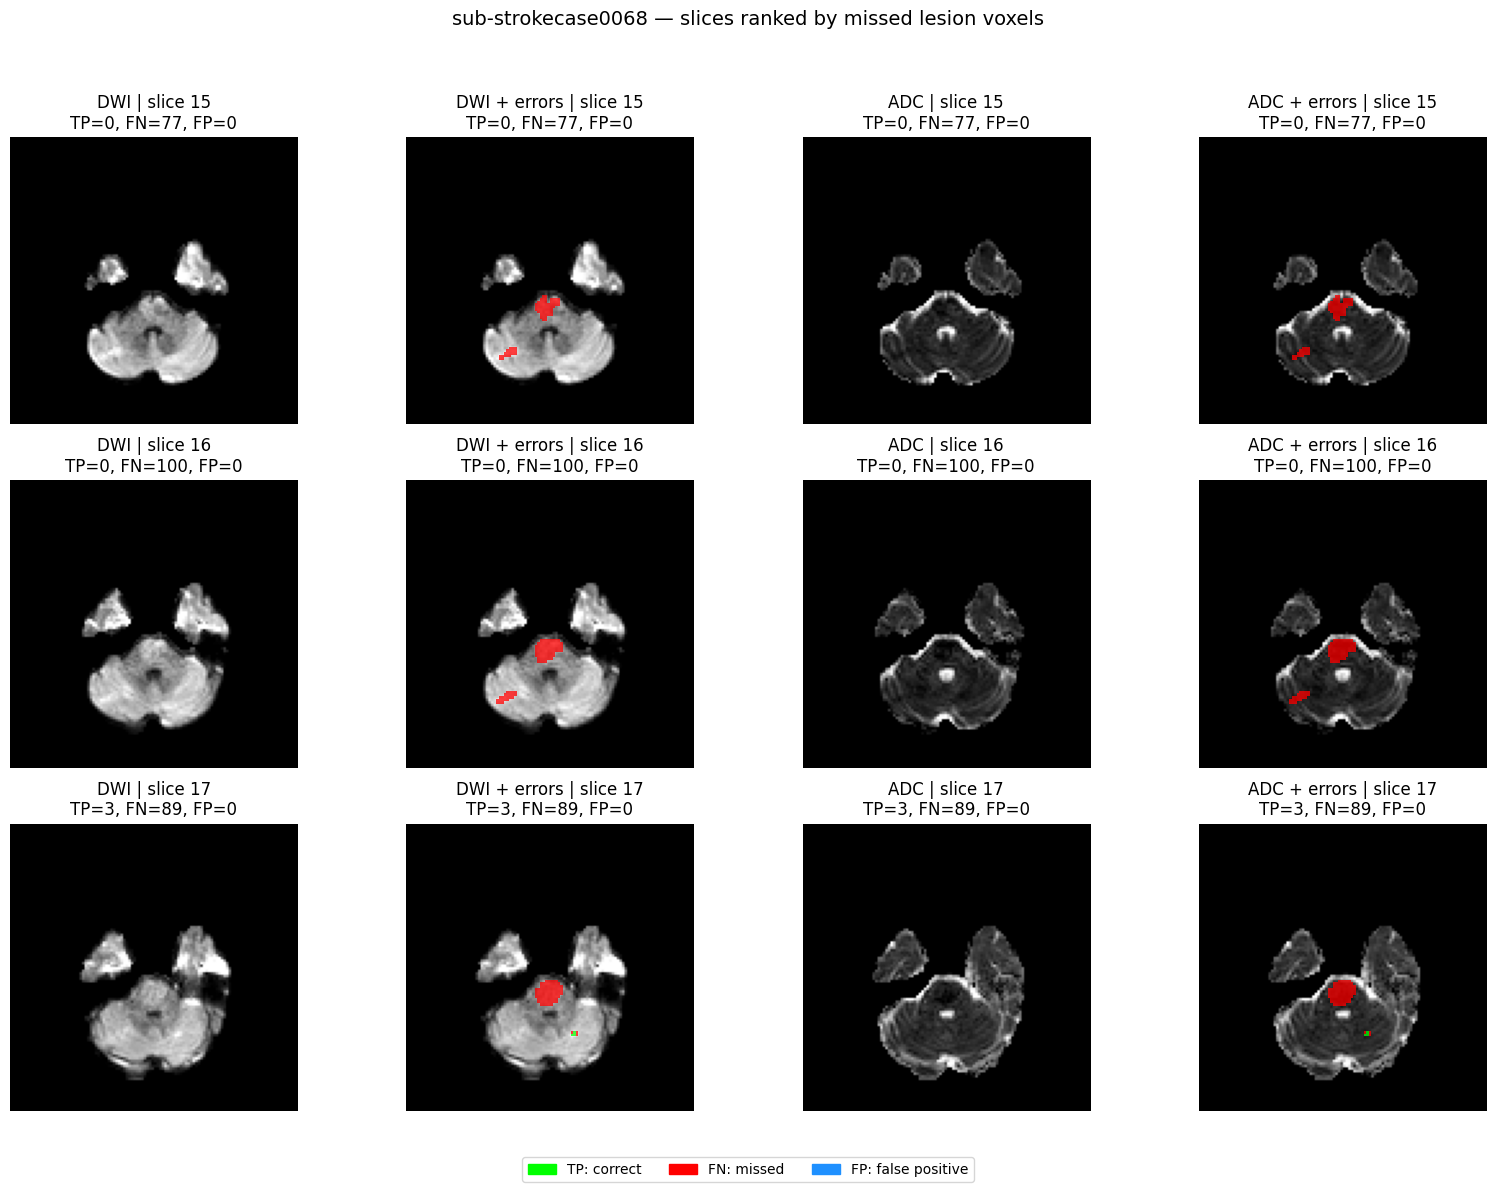


sub-strokecase0098 | 전체 영상 Dice=0.3898 | Recall=35.26%
TP=61, FN=112, FP=79


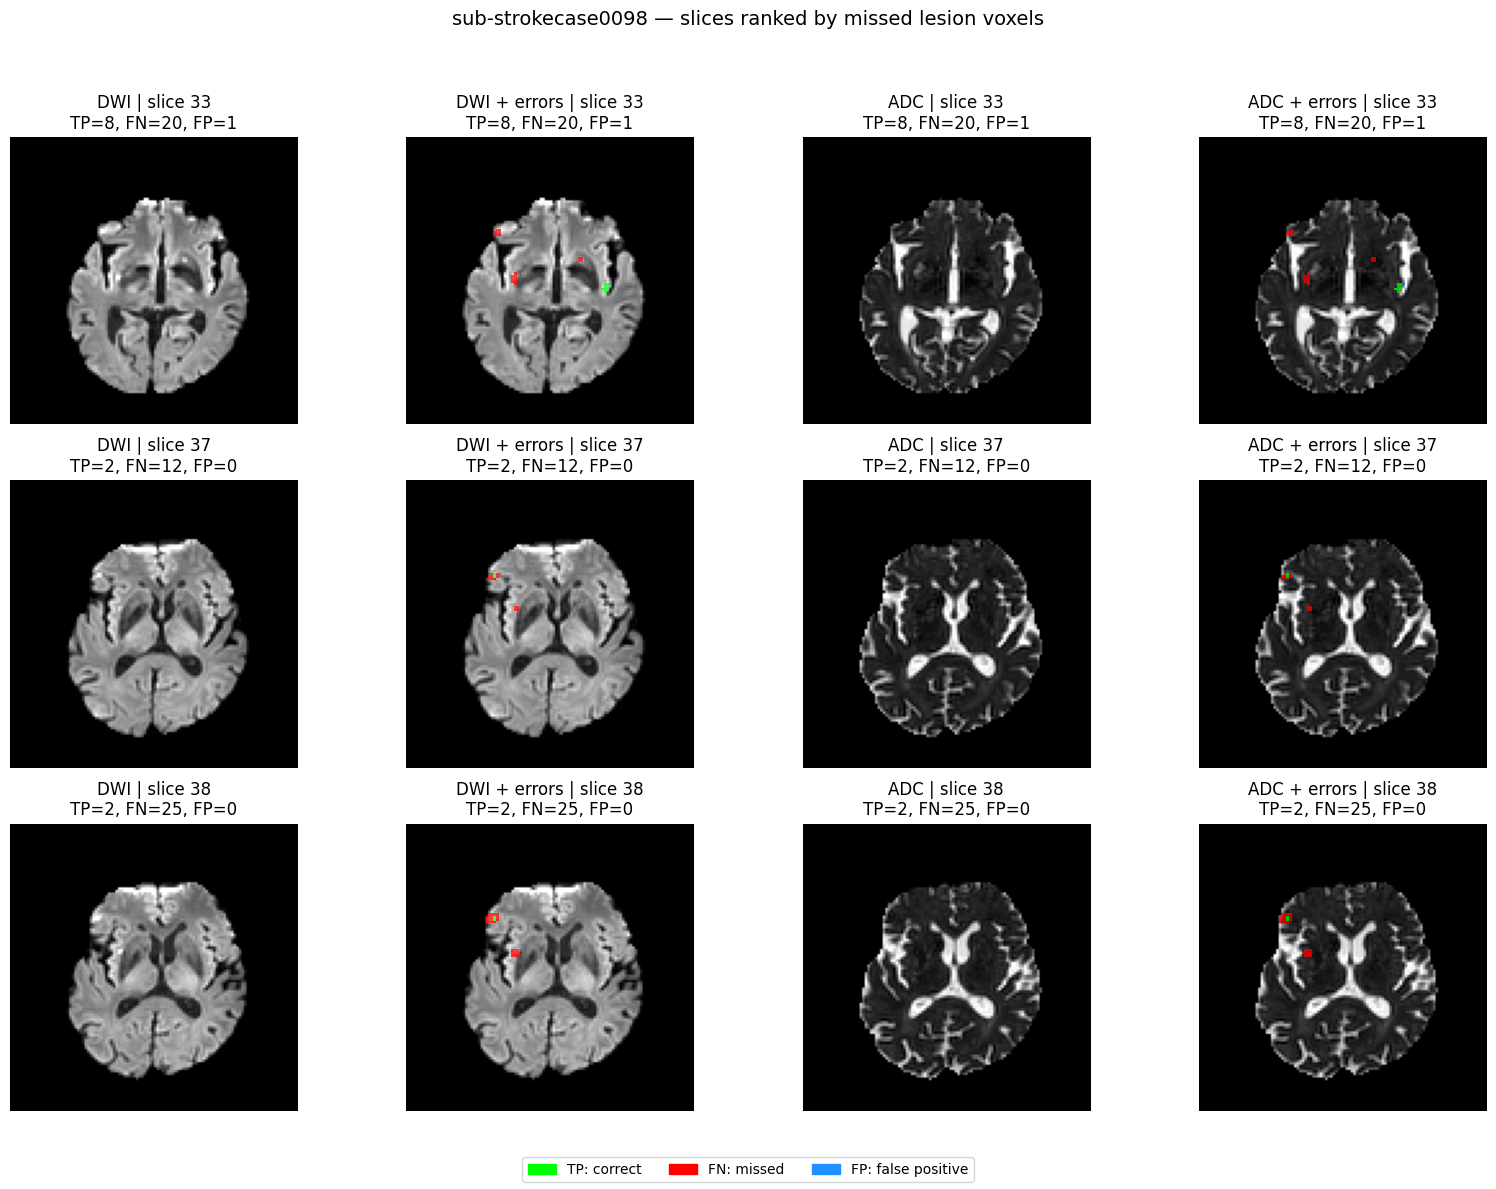

In [ ]:
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pathlib import Path

IMAGE_DIR = Path("/content/brainon_cache/overlay_images")

GT_DIR = Path(
    "/content/brainon_cache/nnUNet_preprocessed/"
    "Dataset502_ISLES2022/gt_segmentations"
)

PRED_DIR = Path(
    "/content/brainon_cache/nnUNet_results/"
    "Dataset502_ISLES2022/"
    "nnUNetTrainerIschemiaBaseline__nnUNetPlans__3d_fullres/"
    "fold_0/validation"
)


def load_canonical(path):
    if not path.is_file():
        raise FileNotFoundError(str(path))
    # 방향을 RAS 기준으로 정리. 원본 파일은 변경하지 않음.
    return nib.as_closest_canonical(nib.load(str(path)))


def read_binary(nii):
    array = np.asarray(nii.dataobj)

    if not np.isfinite(array).all():
        raise ValueError("마스크에 NaN/Inf가 있습니다.")

    near_zero = np.isclose(array, 0, atol=1e-6, rtol=0)
    near_one = np.isclose(array, 1, atol=1e-6, rtol=0)

    if not np.all(near_zero | near_one):
        raise ValueError("마스크에 0/1 이외의 값이 있습니다.")

    return near_one


def check_grid(reference, image, name):
    if len(image.shape) != 3 or image.shape != reference.shape:
        raise ValueError(f"{name}: 영상·마스크 shape가 다릅니다.")

    if not np.allclose(
        reference.affine, image.affine, atol=1e-4, rtol=1e-5
    ):
        raise ValueError(
            f"{name}: 영상·마스크 좌표가 다릅니다. "
            "임의로 겹치지 않고 중단합니다."
        )

    if reference.header.get_xyzt_units()[0] != \
            image.header.get_xyzt_units()[0]:
        raise ValueError(f"{name}: 공간 단위가 다릅니다.")


def window_limits(volume):
    valid = volume[np.isfinite(volume) & (volume != 0)]
    if valid.size == 0:
        raise ValueError("표시 가능한 영상 신호가 없습니다.")

    low, high = np.percentile(valid, [1, 99])
    if high <= low:
        high = low + 1
    return float(low), float(high)


def show_patient(case):
    gt_nii = load_canonical(GT_DIR / f"{case}.nii.gz")
    pred_nii = load_canonical(PRED_DIR / f"{case}.nii.gz")
    dwi_nii = load_canonical(IMAGE_DIR / f"{case}_0000.nii.gz")
    adc_nii = load_canonical(IMAGE_DIR / f"{case}_0001.nii.gz")

    for name, image in [
        ("예측 마스크", pred_nii),
        ("DWI", dwi_nii),
        ("ADC", adc_nii),
    ]:
        check_grid(gt_nii, image, name)

    gt = read_binary(gt_nii)
    pred = read_binary(pred_nii)
    dwi = dwi_nii.get_fdata(dtype=np.float32)
    adc = adc_nii.get_fdata(dtype=np.float32)

    tp = gt & pred
    fn = gt & ~pred
    fp = ~gt & pred

    # RAS로 정리된 배열의 세 번째 축을 따라 단면 선택
    fn_per_slice = fn.sum(axis=(0, 1))
    gt_per_slice = gt.sum(axis=(0, 1))

    candidates = np.flatnonzero(fn_per_slice > 0)
    scores = fn_per_slice

    if not len(candidates):
        candidates = np.flatnonzero(gt_per_slice > 0)
        scores = gt_per_slice

    if not len(candidates):
        print(case, ": 정답 병변이 없습니다.")
        return

    selected = sorted(
        sorted(candidates, key=lambda z: (-int(scores[z]), int(z)))[:3]
    )

    # voxel 간격을 반영해 화면 비율 유지
    spacing = np.linalg.norm(gt_nii.affine[:3, :3], axis=0)
    aspect = spacing[1] / spacing[0]

    dwi_window = window_limits(dwi)
    adc_window = window_limits(adc)

    denominator = int(gt.sum() + pred.sum())
    dice = 2 * int(tp.sum()) / denominator if denominator else np.nan
    recall = int(tp.sum()) / int(gt.sum()) if gt.any() else np.nan

    print(
        f"\n{case} | 전체 영상 Dice={dice:.4f} | "
        f"Recall={recall:.2%}\n"
        f"TP={int(tp.sum())}, FN={int(fn.sum())}, FP={int(fp.sum())}"
    )

    fig, axes = plt.subplots(
        len(selected), 4,
        figsize=(16, 4 * len(selected)),
        squeeze=False,
    )

    for row, z in enumerate(selected):
        overlay = np.zeros(gt[:, :, z].shape + (4,), dtype=np.float32)
        overlay[tp[:, :, z]] = [0.0, 1.0, 0.0, 0.75]
        overlay[fn[:, :, z]] = [1.0, 0.0, 0.0, 0.75]
        overlay[fp[:, :, z]] = [0.0, 0.5, 1.0, 0.75]

        panels = [
            (dwi, dwi_window, False, "DWI"),
            (dwi, dwi_window, True, "DWI + errors"),
            (adc, adc_window, False, "ADC"),
            (adc, adc_window, True, "ADC + errors"),
        ]

        for col, (volume, limits, with_overlay, title) in enumerate(panels):
            ax = axes[row, col]
            ax.imshow(
                volume[:, :, z].T,
                cmap="gray",
                origin="lower",
                vmin=limits[0],
                vmax=limits[1],
                aspect=aspect,
            )
            if with_overlay:
                ax.imshow(
                    overlay.transpose(1, 0, 2),
                    origin="lower",
                    interpolation="nearest",
                    aspect=aspect,
                )

            ax.set_title(
                f"{title} | slice {z}\n"
                f"TP={int(tp[:, :, z].sum())}, "
                f"FN={int(fn[:, :, z].sum())}, "
                f"FP={int(fp[:, :, z].sum())}"
            )
            ax.axis("off")

    fig.suptitle(
        f"{case} — slices ranked by missed lesion voxels",
        fontsize=14,
    )
    fig.legend(
        handles=[
            Patch(color="lime", label="TP: correct"),
            Patch(color="red", label="FN: missed"),
            Patch(color="dodgerblue", label="FP: false positive"),
        ],
        loc="lower center",
        ncol=3,
    )
    fig.tight_layout(rect=[0, 0.05, 1, 0.95])
    plt.show()


for case in ["sub-strokecase0068", "sub-strokecase0098"]:
    show_patient(case)

오버레이 확인 결과, 0068은 일부 단면의 정답 병변을 거의 전부 놓쳤고, 0098은 여러 위치의 정답 영역을 부분적으로 놓쳤다.
평균 Dice 외에 단면·병변별 미탐 분석이 필요하다.”